# 1회차 도전 실습 — 다중 스케일 템플릿 매칭
## 크기 탐색 · 점수 곡선 · 위치 검증 · 실행 시간 · 회전의 한계

**원본:** `s01_multiscale_challenge.py`의 핵심 실험을 독립적으로 실행할 수 있게 구성했습니다. 이 노트북만 열어도 됩니다. 단일 크기 매칭과 0.5~1.6배의 12개 크기 매칭을 비교하고, 설명·수식·시각화·반복 시간 측정을 추가했습니다.

**핵심 질문**

1. 작은 얼굴과 큰 얼굴을 찾기 위해 템플릿의 크기를 함께 바꾸면 도움이 될까요?
2. 탐색하는 크기가 늘면 점수와 시간은 어떻게 달라질까요?
3. 크기를 바꾸는 것만으로 회전도 해결될까요?

규칙을 늘려 탐색 범위를 넓히는 실험입니다. 정답으로 파라미터를 학습하는 신경망 학습은 아닙니다. 최고 점수가 높아져도 올바른 얼굴을 찾았는지 별도로 확인해야 합니다.


## 0. 준비와 재현

필요한 패키지는 `numpy`, `opencv-python`, `matplotlib`, `scikit-image`입니다. Jupyter 환경에서 위에서부터 모두 실행하세요. 첫 노트북의 실행 상태에 의존하지 않습니다. 기본 얼굴 사진은 `skimage.data.astronaut()`입니다.

시간은 컴퓨터 성능, OpenCV 버전, 스레드 설정과 백그라운드 작업에 따라 달라집니다. 아래는 같은 커널에서 워밍업 후 여러 번 측정한 중앙값을 사용합니다. 배포본의 실행 시간은 참고값이며, 실제 비교는 본인 환경에서 다시 실행하세요.


In [1]:
# 필요한 경우에만 주석 해제
# %pip install numpy opencv-python matplotlib scikit-image


In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

plt.rcParams.update({'figure.dpi':110,'font.size':10})
img=cv2.cvtColor(data.astronaut(),cv2.COLOR_RGB2GRAY)
x,y,w,h=177,66,95,95
templ=img[y:y+h,x:x+w].copy()
scales=np.linspace(.5,1.6,12)
print('사진:',img.shape,'| 템플릿:',templ.shape)
print('크기 후보:',np.round(scales,2))
print('OpenCV:',cv2.__version__,'| threads:',cv2.getNumThreads())


사진: (512, 512) | 템플릿: (95, 95)
크기 후보: [0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6]
OpenCV: 4.14.0 | threads: 10


## 1. 단일 크기 매칭 복습

검색 영상 $I$의 위치 $(u,v)$에서 템플릿 크기의 패치를 꺼내 $P_{u,v}$라 합니다. 평균을 뺀 정규화 상관계수는 다음과 같습니다.

$$R(u,v)=\frac{\sum (T-\bar T)(P_{u,v}-\bar P_{u,v})}{\sqrt{\sum(T-\bar T)^2\sum(P_{u,v}-\bar P_{u,v})^2}}$$

합은 템플릿의 모든 픽셀에 대해 계산합니다. 분모가 0이 아닌 경우 점수는 이론적으로 -1~1이며, 클수록 비슷합니다. 상수 템플릿·상수 패치에서는 수학적으로 정의되지 않으므로 주의합니다. 점수는 얼굴일 확률이 아닙니다.

단일 크기 방법은 위치 $(u,v)$만 탐색합니다. `find()`는 최고 점수와 왼쪽 위 좌표 `(x,y)`를 반환합니다. 검색 영상보다 템플릿이 큰 경우를 명시적으로 막습니다. 일반적인 입력 조건을 검사하여 OpenCV의 내부 동작에 의존하지 않도록 합니다.


자기 매칭: 0.999999463558197 (177, 66)


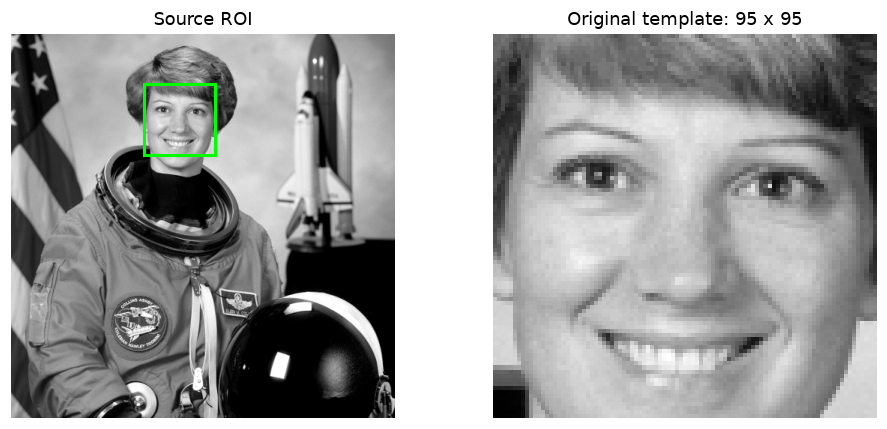

In [3]:
def find(gray,t):
    if gray.ndim!=2 or t.ndim!=2:
        raise ValueError('흑백 2차원 영상을 사용하세요.')
    if t.size==0 or t.shape[0]>gray.shape[0] or t.shape[1]>gray.shape[1]:
        raise ValueError('템플릿이 비었거나 검색 영상보다 큽니다.')
    if t.std()==0:
        raise ValueError('상수 템플릿은 정규화 상관계수에 적합하지 않습니다.')
    res=cv2.matchTemplate(gray,t,cv2.TM_CCOEFF_NORMED)
    _,v,_,loc=cv2.minMaxLoc(res)
    return float(v),loc

score,loc=find(img,templ)
print('자기 매칭:',score,loc)
fig,axes=plt.subplots(1,2,figsize=(9,4))
axes[0].imshow(img,cmap='gray',vmin=0,vmax=255)
axes[0].add_patch(plt.Rectangle((x,y),w,h,fill=False,ec='lime',lw=2))
axes[0].set_title('Source ROI')
axes[1].imshow(templ,cmap='gray',vmin=0,vmax=255)
axes[1].set_title('Original template: 95 x 95')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()


## 2. 크기도 탐색하는 모델

배율 $s$로 크기를 바꾼 템플릿을 $T_s$라 하면, 다음 세 변수를 함께 탐색합니다.

$$ (s^*,u^*,v^*)=\underset{s\in\mathcal S,\,(u,v)\in\Omega_s}{\arg\max}\ R_s(u,v) $$

$\mathcal S=\{0.5,0.6,\ldots,1.6\}$이고, $\Omega_s$는 해당 크기의 템플릿이 영상에 완전히 들어가는 위치들입니다. 각 크기에서 최고점을 찾은 뒤, 그 최고점들 중 가장 큰 값을 선택합니다.

템플릿 배율은 **원래 템플릿을 기준으로 한 배율**입니다. 검색 영상을 0.6배로 축소한 경우에는 얼굴 크기도 줄기 때문에 템플릿 0.6배가 유리할 것으로 예상할 수 있습니다. 검색 영상 크기는 그대로 두고 템플릿을 바꾸므로, 찾은 위치는 이미 검색 영상의 좌표입니다. 이를 다시 s로 나누면 잘못된 좌표가 됩니다.

원본 함수는 전역 변수 `templ`을 참조하지만, 여기서는 함수 인자로 명시적으로 전달합니다. 원본의 선형 보간 기본값 `INTER_LINEAR`를 유지하고, 각 크기의 점수·실제 템플릿 크기·위치를 기록합니다. 축소 시 다른 보간법을 쓰면 결과가 달라질 수 있습니다.


In [4]:
def find_multiscale(gray,template,scales):
    records=[]
    for s in scales:
        if not np.isfinite(s) or s<=0:
            raise ValueError('배율은 유한한 양수여야 합니다.')
        # 원본처럼 fx,fy로 크기 결정. 너무 작은 후보는 건너뜁니다.
        if round(template.shape[0]*s)<1 or round(template.shape[1]*s)<1:
            continue
        t=cv2.resize(template,None,fx=float(s),fy=float(s),interpolation=cv2.INTER_LINEAR)
        th,tw=t.shape
        if th>gray.shape[0] or tw>gray.shape[1] or t.std()==0:
            continue
        v,loc=find(gray,t)
        records.append(dict(scale=float(s),score=v,loc=loc,size=(tw,th)))
    if not records:
        raise ValueError('검색 가능한 템플릿 크기가 없습니다.')
    best=max(records,key=lambda r:r['score'])  # 동점이면 앞의 후보 선택
    return best,records

best,records=find_multiscale(img,templ,scales)
print('원본 사진에서 선택:',best)


원본 사진에서 선택: {'scale': 1.0, 'score': 0.999999463558197, 'loc': (177, 66), 'size': (95, 95)}


### 크기 후보와 픽셀 반올림

95×0.5처럼 소수 크기가 나오면 실제 영상은 정수 픽셀 크기로 만들어집니다. 구현의 반올림과 보간을 거친 실제 `t.shape`를 상자 크기로 사용해야 합니다. `int(w*s)`처럼 잘라 버린 값으로 상자를 그리면 실제 템플릿과 1픽셀 차이가 날 수 있습니다.

아래 그림은 대표 배율의 템플릿입니다. 각 패널은 화면에 맞춰 표시되므로 눈으로 보는 패널 크기가 아니라 제목의 실제 픽셀 크기를 확인하세요. 원래 템플릿에서 직접 각 배율을 만들며, 이전 배율의 결과를 연속으로 확대·축소하지 않습니다.


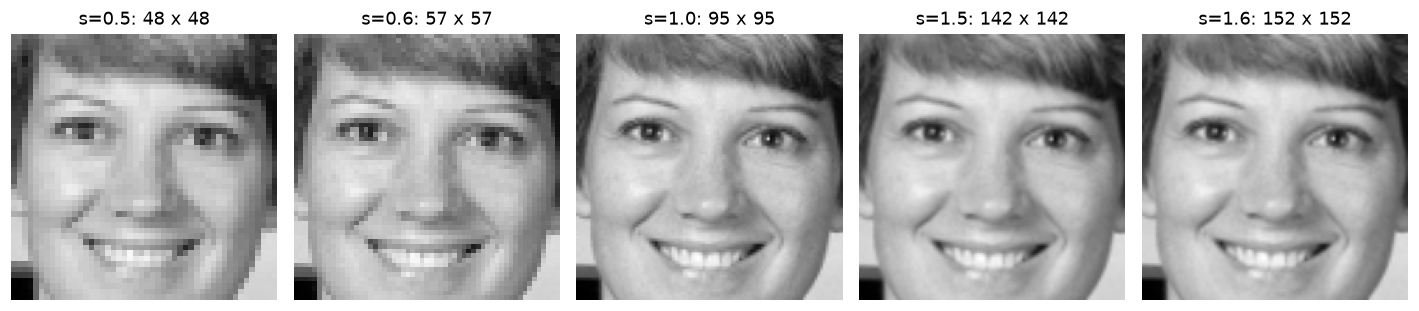

In [5]:
fig,axes=plt.subplots(1,5,figsize=(13,3))
for ax,s in zip(axes,[.5,.6,1.,1.5,1.6]):
    t=cv2.resize(templ,None,fx=s,fy=s)
    ax.imshow(t,cmap='gray',vmin=0,vmax=255)
    ax.set_title(f's={s:.1f}: {t.shape[1]} x {t.shape[0]}')
    ax.axis('off')
plt.tight_layout(); plt.show()


## 3. 평가 영상과 정답 위치 만들기

원본처럼 검색 영상을 0.6배·1.5배로 바꾼 경우와, 얼굴 중심을 기준으로 25도 회전한 경우를 만듭니다.

**크기 변화:** 실제 출력 크기 비율 $s_x=W'/W$, $s_y=H'/H$를 사용해 처음 ROI의 위치와 크기를 변환합니다. 원본의 `int(x*s)`는 빠른 근사입니다. 여기서는 비교용 정답을 소수 좌표로 보관하여 불필요한 절삭을 줄입니다. 리사이즈 보간과 픽셀 중심 좌표 관례 때문에 이 상자는 연속 좌표에서의 기하학적 기준이며, 서브픽셀 수준의 완벽한 정답을 뜻하지 않습니다.

**회전:** 원래 ROI의 네 모서리 $p=(x,y,1)^\mathsf T$에 동일한 아핀 행렬 $M$을 적용합니다.

$$p'=Mp$$

회전된 정답은 사각형이 아니라 **기울어진 다각형**입니다. 원본에 쓰인 `(x,y)`는 회전 전 상자의 왼쪽 위 참고값이며, 회전 후 실제 왼쪽 위 정답이라고 볼 수 없습니다. 회전 중심을 얼굴 중심으로 정했으므로 **중심은 그대로 유지**됩니다. 회전 사례는 다각형을 그려 비교하고 중심 오차를 함께 제시합니다.


In [6]:
H,W=img.shape
corners=np.array([[x,y],[x+w,y],[x+w,y+h],[x,y+h]],dtype=np.float64)
cases=[]
for s in (.6,1.5):
    g=cv2.resize(img,None,fx=s,fy=s)
    factors=np.array([g.shape[1]/W,g.shape[0]/H])
    poly=corners*factors
    gt_box=(x*factors[0],y*factors[1],w*factors[0],h*factors[1])
    cases.append(dict(name=f'Scale x{s}',image=g,poly=poly,gt_box=gt_box,expected_scale=s))

center=(x+w/2,y+h/2)
M=cv2.getRotationMatrix2D(center,25,1.)
rotated=cv2.warpAffine(img,M,(W,H))
rot_poly=np.column_stack([corners,np.ones(4)])@M.T
cases.append(dict(name='Rotation 25 deg',image=rotated,poly=rot_poly,gt_box=None,expected_scale=None))
for c in cases:
    c['gt_center']=c['poly'].mean(axis=0)
    print(c['name'],c['image'].shape,'| expected center:',np.round(c['gt_center'],2))


Scale x0.6 (307, 307) | expected center: [134.61  68.06]
Scale x1.5 (768, 768) | expected center: [336.75 170.25]
Rotation 25 deg (512, 512) | expected center: [224.5 113.5]


## 4. 단일 크기와 12개 크기 비교

각 방법에 대해 최고 점수, 위치, 예측 크기, 중심 오차를 기록합니다. 축소·확대 사례에는 처음 ROI를 변환한 상자와의 IoU도 계산합니다. 회전 사례의 다각형을 축에 정렬된 상자로 바꿔 동일한 정답처럼 쓰면 평가 의미가 달라지므로, 이 노트북에서는 회전 IoU를 계산하지 않습니다.

중심 오차만 작아도 크기·회전이 맞았다는 보장은 없습니다. 점수·그림·상자 겹침을 함께 해석해야 합니다. 두 방법 모두 같은 검색 영상과 원래 템플릿에서 시작합니다.


In [7]:
def box_iou(a,b):
    ax,ay,aw,ah=a; bx,by,bw,bh=b
    inter=max(0,min(ax+aw,bx+bw)-max(ax,bx))*max(0,min(ay+ah,by+bh)-max(ay,by))
    return inter/(aw*ah+bw*bh-inter)

def evaluate_record(r,case):
    px,py=r['loc']; tw,th=r['size']
    r=dict(r)
    r['center_error']=float(np.linalg.norm(np.array([px+tw/2,py+th/2])-case['gt_center']))
    r['iou']=box_iou((px,py,tw,th),case['gt_box']) if case['gt_box'] is not None else float('nan')
    return r

for c in cases:
    v,loc=find(c['image'],templ)
    c['single']=evaluate_record(dict(score=v,loc=loc,scale=1.,size=(w,h)),c)
    best,curve=find_multiscale(c['image'],templ,scales)
    c['multi']=evaluate_record(best,c)
    c['curve']=curve
    print('\n'+c['name'])
    for method in ('single','multi'):
        r=c[method]
        print(f'{method:6} score={r["score"]:.4f}, scale={r["scale"]:.2f}, loc={r["loc"]}, '
              f'size={r["size"]}, center_error={r["center_error"]:.2f}px, IoU={r["iou"]:.3f}')



Scale x0.6
single score=0.5806, scale=1.00, loc=(164, 36), size=(95, 95), center_error=78.42px, IoU=0.000
multi  score=0.9809, scale=0.60, loc=(106, 40), size=(57, 57), center_error=0.46px, IoU=0.981

Scale x1.5
single score=0.5563, scale=1.00, loc=(673, 35), size=(95, 95), center_error=393.65px, IoU=0.000
multi  score=0.9966, scale=1.50, loc=(266, 99), size=(142, 142), center_error=0.35px, IoU=0.993

Rotation 25 deg
single score=0.5592, scale=1.00, loc=(318, 27), size=(95, 95), center_error=146.29px, IoU=nan
multi  score=0.5967, scale=0.50, loc=(355, 33), size=(48, 48), center_error=164.51px, IoU=nan


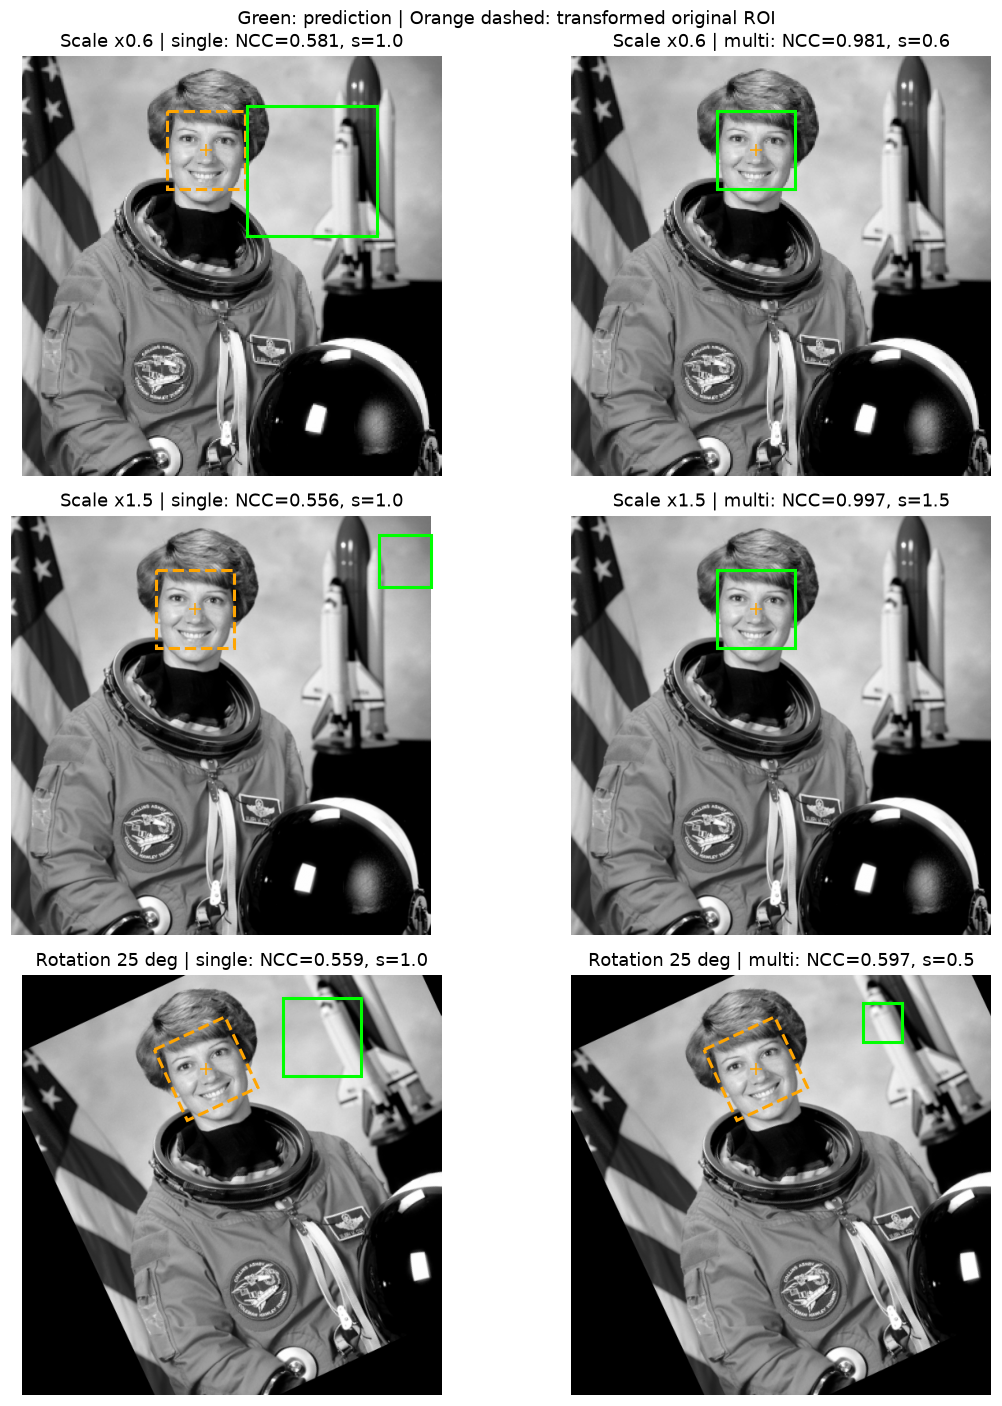

In [8]:
fig,axes=plt.subplots(3,2,figsize=(11,13))
for row,c in enumerate(cases):
    for col,method in enumerate(('single','multi')):
        ax=axes[row,col]; r=c[method]
        ax.imshow(c['image'],cmap='gray',vmin=0,vmax=255)
        ax.add_patch(plt.Polygon(c['poly'],closed=True,fill=False,ec='orange',ls='--',lw=2))
        ax.add_patch(plt.Rectangle(r['loc'],*r['size'],fill=False,ec='lime',lw=2))
        ax.plot(*c['gt_center'],'+',color='orange',ms=8)
        ax.set_title(f"{c['name']} | {method}: NCC={r['score']:.3f}, s={r['scale']:.1f}")
        ax.axis('off')
fig.suptitle('Green: prediction | Orange dashed: transformed original ROI')
plt.tight_layout(); plt.show()


## 5. 배율별 최고 점수 곡선

각 후보 배율에서 위치를 전부 탐색한 최고 점수를 다음처럼 정의합니다.

$$q(s)=\max_{u,v}R_s(u,v)$$

이 그래프의 가로축은 **템플릿 배율**, 세로축은 **해당 배율에서 영상 전체의 최고 상관계수**입니다. 학습 횟수에 따른 손실 그래프가 아닙니다. 작은 점수보다는 큰 점수를 찾으며, 곡선의 각 점이 서로 다른 위치를 가리킬 수 있습니다.

확대·축소 사례에서 기대 배율 근처의 점수가 큰지 확인하세요. 전체 사진을 리사이즈한 뒤 자르는 것과 원래 작은 템플릿만 리사이즈하는 것은 경계·보간·위치 반올림이 다르므로 기대 배율에서도 점수가 정확히 1일 필요는 없습니다.

회전 사례는 탐색 변수에 각도가 없습니다. 어느 s에서 최고가 나오더라도 그것이 25도 회전을 보정했다는 뜻은 아닙니다. 다른 크기나 다른 부위가 우연히 더 높은 점수를 줄 수도 있습니다.


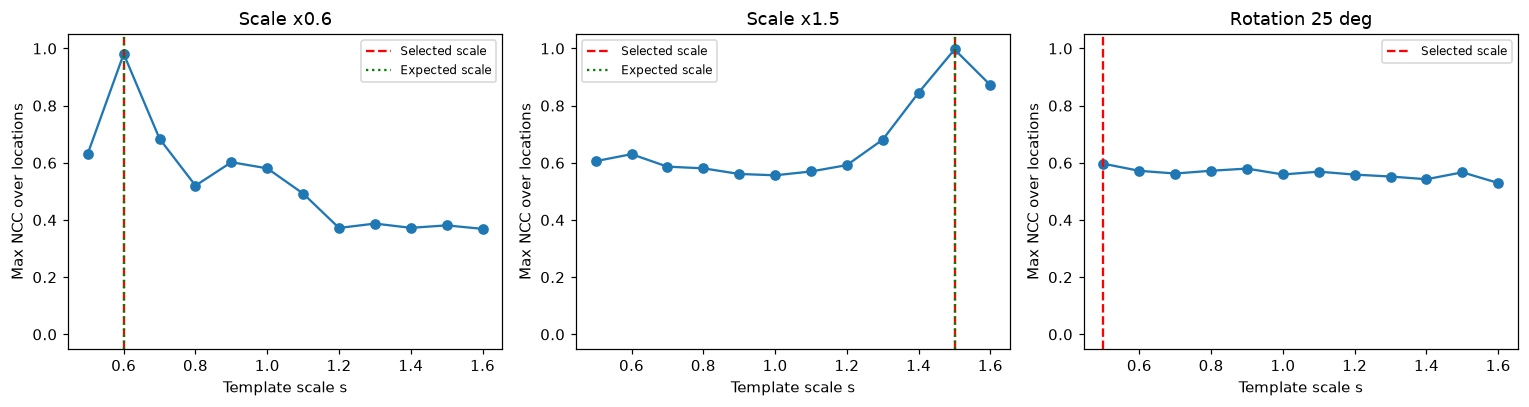

In [9]:
fig,axes=plt.subplots(1,3,figsize=(14,3.8))
for ax,c in zip(axes,cases):
    ax.plot([r['scale'] for r in c['curve']],[r['score'] for r in c['curve']],'o-')
    ax.axvline(c['multi']['scale'],color='r',ls='--',label='Selected scale')
    if c['expected_scale'] is not None:
        ax.axvline(c['expected_scale'],color='g',ls=':',label='Expected scale')
    ax.set(title=c['name'],xlabel='Template scale s',ylabel='Max NCC over locations',ylim=(-.05,1.05))
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 6. 시간은 얼마나 늘어날까?

단순한 직접 계산을 가정하면 크기 $s$에서 위치 수는 $(H-h_s+1)(W-w_s+1)$이고, 위치마다 $h_sw_s$개의 픽셀을 비교합니다. 따라서 개략적인 연산량은 다음과 같습니다.

$$C_{\mathrm{multi}}\propto\sum_{s\in\mathcal S}(H-h_s+1)(W-w_s+1)h_sw_s$$

이 식은 개념 설명용입니다. OpenCV는 내부 최적화와 효율적인 상관 계산을 사용하므로 이 식으로 실제 시간을 정확히 예측할 수 없습니다. 템플릿 크기마다 비용이 다르고 리사이즈 비용도 있으므로 **12개 크기 = 정확히 12배 시간**은 아닙니다.

원본은 각 방법을 한 번 측정합니다. 여기서는 1회 워밍업 후 5회 반복하여 중앙값과 최소·최대 시간을 기록합니다. 다중 스케일 시간에는 템플릿 리사이즈·입력 검사·기록 생성이 포함되며, 그림 그리기와 이미지 생성은 포함하지 않습니다. 이는 이 노트북 함수 전체의 비용이며 OpenCV 내부 매칭 연산만의 벤치마크는 아닙니다. 측정 순서와 일시적인 시스템 부하의 영향도 남습니다.


case                single median(ms)  multi median(ms)  ratio
Scale x0.6                   1.04              15.93     15.35x


Scale x1.5                   9.51             133.11     14.00x


Rotation 25 deg              3.44              44.84     13.05x


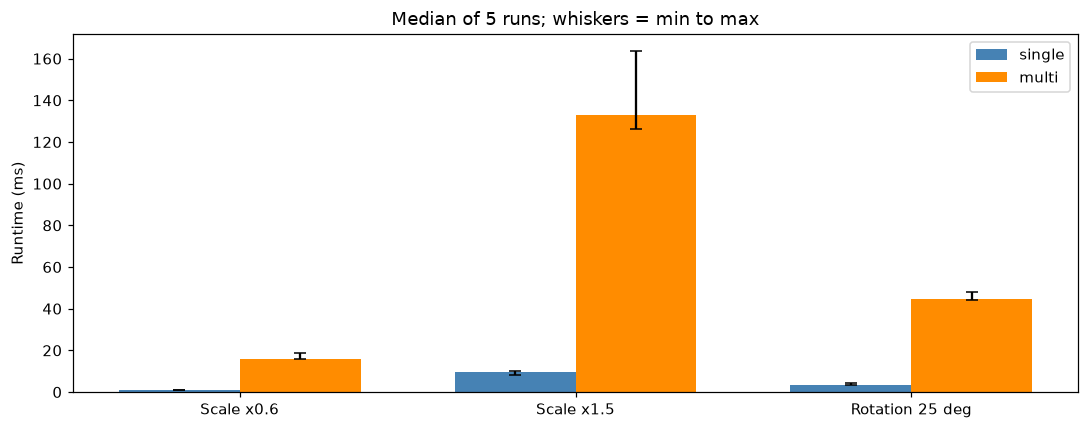

In [10]:
def benchmark(fn,repeats=5):
    fn()  # 워밍업
    samples=[]
    for _ in range(repeats):
        t0=time.perf_counter()
        fn()
        samples.append((time.perf_counter()-t0)*1000)
    return np.array(samples)

print('case                single median(ms)  multi median(ms)  ratio')
for c in cases:
    g=c['image']
    c['single_times']=benchmark(lambda:find(g,templ))
    c['multi_times']=benchmark(lambda:find_multiscale(g,templ,scales))
    a=np.median(c['single_times']); b=np.median(c['multi_times'])
    print(f'{c["name"]:<20} {a:12.2f}       {b:12.2f}     {b/a:5.2f}x')

fig,ax=plt.subplots(figsize=(10,4))
positions=np.arange(len(cases)); width=.36
for shift,method,color in [(-width/2,'single','steelblue'),(width/2,'multi','darkorange')]:
    samples=[c[method+'_times'] for c in cases]
    med=np.array([np.median(a) for a in samples])
    low=med-np.array([a.min() for a in samples])
    high=np.array([a.max() for a in samples])-med
    ax.bar(positions+shift,med,width,label=method,color=color,yerr=np.array([low,high]),capsize=4)
ax.set_xticks(positions,[c['name'] for c in cases])
ax.set(ylabel='Runtime (ms)',title='Median of 5 runs; whiskers = min to max')
ax.legend(); plt.tight_layout(); plt.show()


## 7. 추가 실험 — 후보를 촘촘하게 하면?

원래 12개 후보의 간격은 0.1입니다. 실제 대상 크기가 0.73배면 후보에 정확히 들어 있지 않습니다. 0.5~1.6 범위를 6개·12개·23개·45개 후보로 나누어 최고 점수와 시간을 비교합니다. 여기서 후보 수는 요청한 배율 수이며, 정수 크기 반올림으로 같은 템플릿 크기가 중복될 수도 있습니다.

후보 집합이 이전 후보를 **모두 포함**할 때에는 탐색한 최대 점수가 작아지지 않습니다. 단순히 후보 개수만 늘리고 격자 위치를 바꾸면 집합이 포함 관계가 아닐 수 있으므로 단조 증가가 보장되지 않습니다. 아래 12→23→45는 더 촘촘한 포함 관계지만, 6→12는 그런 관계가 아닙니다.

점수가 높아지는 것과 올바른 위치를 찾는 것은 별개입니다. 후보를 많이 시험하면 우연한 높은 점수도 선택될 수 있습니다. 실무에서는 대상이 없는 이미지와 위치 정답을 포함한 검증이 필요합니다.


n= 6, selected=0.7200, score=0.9773, median=16.84ms, center_error=0.09px


n=12, selected=0.7000, score=0.9150, median=32.80ms, center_error=0.91px


n=23, selected=0.7500, score=0.9577, median=56.67ms, center_error=0.64px


n=45, selected=0.7250, score=0.9769, median=108.27ms, center_error=0.64px


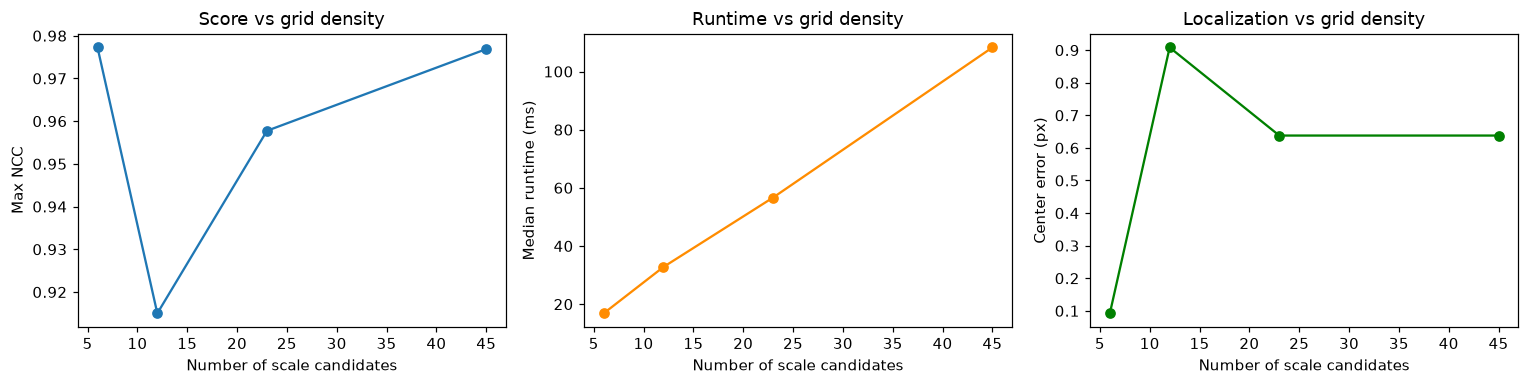

In [11]:
probe=cv2.resize(img,None,fx=.73,fy=.73)
probe_f=np.array([probe.shape[1]/W,probe.shape[0]/H])
probe_gt=np.array([x+w/2,y+h/2])*probe_f
counts=[6,12,23,45]
density=[]
for n in counts:
    grid=np.linspace(.5,1.6,n)
    b,_=find_multiscale(probe,templ,grid)
    times=benchmark(lambda:find_multiscale(probe,templ,grid),repeats=3)
    center_error=float(np.linalg.norm(np.array(b['loc'])+np.array(b['size'])/2-probe_gt))
    density.append(dict(n=n,score=b['score'],scale=b['scale'],ms=float(np.median(times)),error=center_error))
    print(f'n={n:2d}, selected={b["scale"]:.4f}, score={b["score"]:.4f}, median={np.median(times):.2f}ms, center_error={center_error:.2f}px')

fig,axes=plt.subplots(1,3,figsize=(14,3.6))
axes[0].plot(counts,[r['score'] for r in density],'o-')
axes[0].set(xlabel='Number of scale candidates',ylabel='Max NCC',title='Score vs grid density')
axes[1].plot(counts,[r['ms'] for r in density],'o-',color='darkorange')
axes[1].set(xlabel='Number of scale candidates',ylabel='Median runtime (ms)',title='Runtime vs grid density')
axes[2].plot(counts,[r['error'] for r in density],'o-',color='green')
axes[2].set(xlabel='Number of scale candidates',ylabel='Center error (px)',title='Localization vs grid density')
plt.tight_layout(); plt.show()


## 8. 추가 실험 — 회전 각도를 늘려 보기

검색 영상을 얼굴 중심 기준으로 -40~40도 회전하고, 단일 크기와 다중 스케일의 최고 점수를 비교합니다. **회전된 검색 영상을 만든 것**이지, 알고리즘에 회전 후보를 추가한 것이 아닙니다. 두 방법 모두 회전 각도를 탐색하지 않습니다.

회전이 커져도 점수가 단조롭게 감소한다고 보장할 수 없습니다. 다른 부위에서 우연히 높은 점수가 나올 수 있기 때문입니다. 중심 오차 그래프를 함께 읽고, 중심이 맞더라도 패턴 방향은 다를 수 있다는 점을 기억하세요. `warpAffine()`은 원본과 같은 출력 크기를 사용하고 영상 바깥을 검게 채우므로, 큰 회전에서는 경계 효과도 생깁니다.


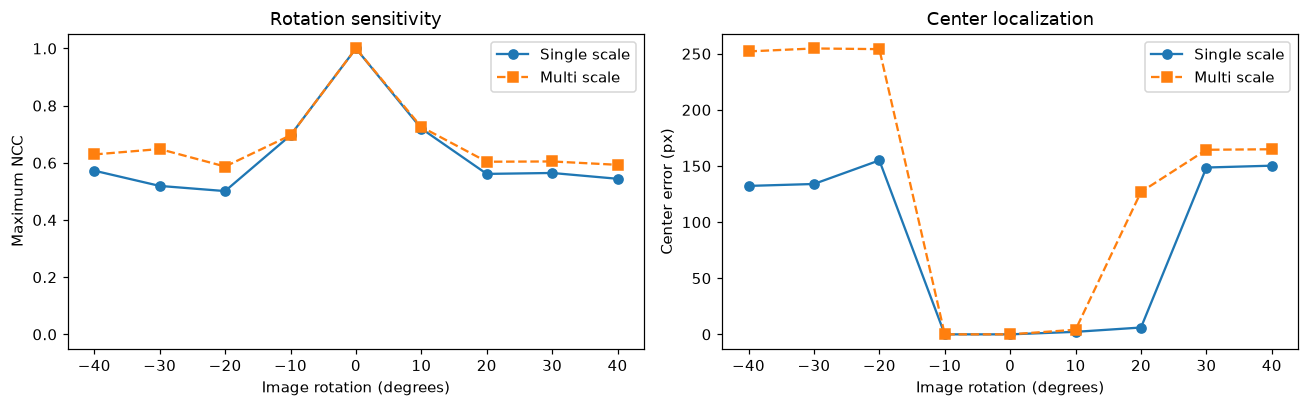

In [12]:
angles=np.arange(-40,41,10)
rotation_rows=[]
for angle in angles:
    matrix=cv2.getRotationMatrix2D(center,float(angle),1.)
    g=cv2.warpAffine(img,matrix,(W,H))
    v,loc=find(g,templ)
    b,_=find_multiscale(g,templ,scales)
    e1=float(np.linalg.norm(np.array(loc)+np.array([w,h])/2-np.array(center)))
    e2=float(np.linalg.norm(np.array(b['loc'])+np.array(b['size'])/2-np.array(center)))
    rotation_rows.append((v,b['score'],e1,e2))
rotation_rows=np.array(rotation_rows)
fig,axes=plt.subplots(1,2,figsize=(12,3.8))
for col,label,style in [(0,'Single scale','o-'),(1,'Multi scale','s--')]:
    axes[0].plot(angles,rotation_rows[:,col],style,label=label)
    axes[1].plot(angles,rotation_rows[:,col+2],style,label=label)
axes[0].set(xlabel='Image rotation (degrees)',ylabel='Maximum NCC',title='Rotation sensitivity',ylim=(-.05,1.05))
axes[1].set(xlabel='Image rotation (degrees)',ylabel='Center error (px)',title='Center localization')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()


## 9. 크기와 각도를 모두 탐색한다면?

각도 집합을 $\Theta$라 할 때, 회전·크기 후보 템플릿 $T_{s,\theta}$를 준비해 다음 탐색을 생각할 수 있습니다.

$$ (s^*,\theta^*,u^*,v^*)=\arg\max_{s\in\mathcal S,\theta\in\Theta,(u,v)\in\Omega_{s,\theta}}R_{s,\theta}(u,v) $$

배율 12개와 각도 9개만 사용해도 템플릿 후보는 108개입니다. 각 후보마다 위치 탐색이 필요합니다. 크기·회전뿐 아니라 시점·표정·사람의 차이까지 템플릿으로 나열하면 후보 수가 크게 늘어납니다.

템플릿을 회전할 때는 잘린 모서리·검은 패딩·유효 영역 마스크 문제도 함께 설계해야 합니다. 단순히 95×95 틀 안에서 회전하면 얼굴 일부가 잘릴 수 있습니다. 따라서 후보 수만 늘린다고 문제가 자동으로 해결되는 것은 아닙니다.

이러한 한계는 다양한 입력에서 유용한 특징을 데이터로 학습하는 방법으로 이어집니다. 다만 학습 모델 역시 충분한 데이터와 독립적인 평가가 필요합니다. 이번 결과만으로 다른 사람의 얼굴을 ‘절대 못 찾는다’고 단정하거나, 반대로 일반적인 얼굴 검출이 된다고 해석하지 않습니다.


## 10. 과제와 확인 문제 해설

**Q1. 크기를 바꿔서 좋아진 것은 무엇인가요?**  
위치뿐 아니라 템플릿의 공간 크기도 탐색하므로 대상 크기에 맞는 패턴을 비교할 수 있습니다. 확대·축소 사례의 최고 점수, 위치 그림, IoU로 확인하세요. 크기 변화 전체에 대한 완벽한 불변성을 얻은 것은 아닙니다.

**Q2. 왜 정확히 12배 느려지지 않나요?**  
후보마다 크기·가능 위치 수·OpenCV 내부 연산 비용이 다르고 리사이즈와 Python 함수 처리도 포함되기 때문입니다. 시간 중앙값의 비율을 본인 환경에서 기록하세요.

**Q3. 찾은 배율이 사진의 배율과 다르면 무조건 실패인가요?**  
후보 격자, 반올림, 보간 때문에 조금 다를 수 있습니다. 실제 상자와 중심 위치를 함께 확인해야 합니다. 큰 차이는 엉뚱한 패턴을 선택했다는 신호일 수도 있습니다.

**Q4. 회전 25도의 정답을 왜 (177,66)으로 쓰지 않나요?**  
그 값은 원래 상자의 왼쪽 위입니다. 회전 후 모서리는 아핀 변환으로 이동합니다. 이 실험에서는 중심을 고정했으므로 중심 비교는 가능하지만 회전된 네 모서리를 다각형으로 다루어야 합니다.

**Q5. 다중 스케일에서 점수가 높으면 회전도 해결한 건가요?**  
아닙니다. 각도 탐색을 하지 않았습니다. 다른 크기의 패턴이 우연히 더 높은 상관을 보일 수 있습니다. 점수는 검출 성공 여부를 직접 뜻하지 않습니다.

**Q6. 이 실습에서 학습되는 파라미터가 있나요?**  
사람이 정한 템플릿과 후보 규칙을 이용해 입력별 최고 위치와 배율을 검색합니다. 정답 데이터로 모델 파라미터를 갱신하지 않습니다. 이전 임계값 실습의 지도학습과 차이를 말해 보세요.

### 직접 해 볼 과제

1. 탐색 범위를 0.8~1.2로 제한하세요. 0.6배 사례를 놓치는지 점수·위치로 확인하세요.
2. 0.73배 사례에서 후보 수를 바꿔 점수·중심 오차·시간을 함께 기록하세요.
3. 템플릿 축소 보간을 `INTER_AREA`로 바꾸고 크기별 결과를 비교하세요. 보간 외 조건은 같게 유지하세요.
4. 얼굴이 없는 다른 영상에서도 최고점을 구하세요. 높은 점수를 얻는 것과 얼굴 검출 성공을 구분하세요.
5. 시간이 허용되면 각도 후보를 추가하되, 회전 템플릿의 패딩과 정답 좌표 정의를 먼저 정하세요.

| 조건 | 후보 수 | 선택 배율 | 최고 NCC | 중심 오차 | IoU(크기 사례) | 중앙 실행 시간 |
|---|---|---|---|---|---|---|
| 0.6배 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 |
| 1.5배 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 |
| 회전 25도 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 해당 없음 | 직접 기록 |

한 장을 변형한 합성 실험은 크기·회전에 대한 성질을 관찰하는 데 적합하지만, 다양한 실제 얼굴에 대한 검출 성능을 검증하는 데이터 세트는 아닙니다.


In [13]:
assert templ.shape==(95,95) and templ.std()>0
assert len(scales)==12 and np.isclose(scales[0],.5) and np.isclose(scales[-1],1.6)
assert len(cases)==3 and len(density)==4
assert np.allclose(rot_poly.mean(axis=0),center)
for c in cases:
    assert len(c['curve'])>0
    assert c['multi']['score']>=c['single']['score']-1e-5  # 이번 격자는 1.0 포함
    for method in ('single','multi'):
        r=c[method]; px,py=r['loc']; tw,th=r['size']
        assert 0<=px<=c['image'].shape[1]-tw
        assert 0<=py<=c['image'].shape[0]-th
print('후보·정답 중심 변환·검색 범위·점수 일관성 확인 완료')


후보·정답 중심 변환·검색 범위·점수 일관성 확인 완료
